#### **First of All we start with the most important step: Cleaning the Data**

In [1267]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams["figure.figsize"] = (20, 10)

In [1268]:
df = pd.read_csv("bengaluru_house_prices.csv")
df.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [1269]:
df.shape

(13320, 9)

In [1270]:
df.groupby('area_type')['area_type'].agg('count')

area_type
Built-up  Area          2418
Carpet  Area              87
Plot  Area              2025
Super built-up  Area    8790
Name: area_type, dtype: int64

In [1271]:
df2 = df.drop(['area_type', 'society', 'balcony', 'availability'], axis='columns')
df2.head()

,location,size,total_sqft,bath,price
0,Electronic City Phase II,2 BHK,1056,2.0,39.07
1,Chikka Tirupathi,4 Bedroom,2600,5.0,120.00
2,Uttarahalli,3 BHK,1440,2.0,62.00
3,Lingadheeranahalli,3 BHK,1521,3.0,95.00
4,Kothanur,2 BHK,1200,2.0,51.00


In [1272]:
df2.isnull().sum()

location       1
size          16
total_sqft     0
bath          73
price          0
dtype: int64

In [1273]:
df3 = df2.dropna()
df3.shape

(13246, 5)

In [1274]:
df3['size'].unique()

array(['2 BHK', '4 Bedroom', '3 BHK', '4 BHK', '6 Bedroom', '3 Bedroom',
       '1 BHK', '1 RK', '1 Bedroom', '8 Bedroom', '2 Bedroom',
       '7 Bedroom', '5 BHK', '7 BHK', '6 BHK', '5 Bedroom', '11 BHK',
       '9 BHK', '9 Bedroom', '27 BHK', '10 Bedroom', '11 Bedroom',
       '10 BHK', '19 BHK', '16 BHK', '43 Bedroom', '14 BHK', '8 BHK',
       '12 Bedroom', '13 BHK', '18 Bedroom'], dtype=object)

In [1275]:
df3['bhk'] = df3['size'].apply(lambda x: int(x.split(' ')[0])) #for example 2BHK is the same as 2 bedrooms so we need to fix this probleme so the model won't mistake
df3.head()

C:\Users\admin\AppData\Local\Temp\ipykernel_6340\1658131487.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df3['bhk'] = df3['size'].apply(lambda x: int(x.split(' ')[0])) #for example 2BHK is the same as 2 bedrooms so we need to fix this probleme so the model won't mistake


,location,size,total_sqft,bath,price,bhk
0,Electronic City Phase II,2 BHK,1056,2.0,39.07,2
1,Chikka Tirupathi,4 Bedroom,2600,5.0,120.00,4
2,Uttarahalli,3 BHK,1440,2.0,62.00,3
3,Lingadheeranahalli,3 BHK,1521,3.0,95.00,3
4,Kothanur,2 BHK,1200,2.0,51.00,2


In [1276]:
df3['bhk'].unique()

array([ 2,  4,  3,  6,  1,  8,  7,  5, 11,  9, 27, 10, 19, 16, 43, 14, 12,
       13, 18], dtype=int64)

In [1277]:
df3[df3.bhk>20] #is not logical that an estate have more than 20 bedrooms

,location,size,total_sqft,bath,price,bhk
1718,2Electronic City Phase II,27 BHK,8000,27.0,230.0,27
4684,Munnekollal,43 Bedroom,2400,40.0,660.0,43


In [1278]:
df3.total_sqft.unique() #we have 1133 - 1384 this is a range not a number so we should fix it

array(['1056', '2600', '1440', ..., '1133 - 1384', '774', '4689'],
      dtype=object)

In [1279]:
def is_float (x):
    try:
        float(x)   # tries to convert x into a float number
    except:
        return False
    return True  #this to verify if x is a number used for the cas of total_sqft

In [1280]:
df3[~df3['total_sqft'].apply(is_float)].head(20) # ~ (tilde) → logical NOT operator

,location,size,total_sqft,bath,price,bhk
30,Yelahanka,4 BHK,2100 - 2850,4.0,186.000,4
122,Hebbal,4 BHK,3067 - 8156,4.0,477.000,4
137,8th Phase JP Nagar,2 BHK,1042 - 1105,2.0,54.005,2
165,Sarjapur,2 BHK,1145 - 1340,2.0,43.490,2
188,KR Puram,2 BHK,1015 - 1540,2.0,56.800,2
410,Kengeri,1 BHK,34.46Sq. Meter,1.0,18.500,1
549,Hennur Road,2 BHK,1195 - 1440,2.0,63.770,2
648,Arekere,9 Bedroom,4125Perch,9.0,265.000,9
661,Yelahanka,2 BHK,1120 - 1145,2.0,48.130,2
672,Bettahalsoor,4 Bedroom,3090 - 5002,4.0,445.000,4


In [1281]:
def convert_sqft_to_num(x):
    try:
        # Case 1: It's a range like "3090 - 5002"
        if '-' in x:
            tokens = x.split('-')
            return (float(tokens[0]) + float(tokens[1])) / 2

        # Case 2: Has other units (Sq. Meter, Sq. Yards, Acres, Perch)
        x = x.lower()

        # Known conversions to square feet
        unit_conversions = {
            "sq. meter": 10.7639,
            "sq. meters": 10.7639,
            "sqm": 10.7639,
            "sq. yard": 9,
            "sq. yards": 9,
            "acre": 43560,
            "acres": 43560,
            "perch": 272.25,  # 1 perch ≈ 272.25 sq.ft
            "perches": 272.25
        }

        # Check if the string contains any known unit
        for unit, factor in unit_conversions.items():
            if unit in x:
                tokens = x.split(unit)
                num = float(tokens[0])
                return num * factor

        # If just a number without units
        return float(x)

    except:
        return None


# def convert_sqft_to_num(x):
#     tokens = x.split('-')
#     if len(tokens) == 2:
#         return (float(tokens[0])+float(tokens[1]))/2
#     try:
#         return float(x)
#     except:
#         return None   

In [1282]:
df4 = df3.copy()
df4['total_sqft'] = df4['total_sqft'].apply(convert_sqft_to_num)
df4.loc[872]

location      Singapura Village
size                      2 BHK
total_sqft               9900.0
bath                        2.0
price                      45.0
bhk                           2
Name: 872, dtype: object

In [1283]:
df5 = df4.copy()
df5['price_per_sqft'] = df5['price']*100000/df5['total_sqft'] #this is important we price wich is the total price of the house (in lac: 100000 indian rupies)
df5.head()

,location,size,total_sqft,bath,price,bhk,price_per_sqft
0,Electronic City Phase II,2 BHK,1056.0,2.0,39.07,2,3699.810606
1,Chikka Tirupathi,4 Bedroom,2600.0,5.0,120.00,4,4615.384615
2,Uttarahalli,3 BHK,1440.0,2.0,62.00,3,4305.555556
3,Lingadheeranahalli,3 BHK,1521.0,3.0,95.00,3,6245.890861
4,Kothanur,2 BHK,1200.0,2.0,51.00,2,4250.000000


In [1284]:
len(df5.location.unique()) #1304 locations -> 1303 dummies too much dimensionalty

1304

In [1285]:
df5.location = df5.location.apply(lambda x: x.strip()) #to get rid of the whitespace (extra spaces)
location_stats = df5.groupby('location')['location'].agg('count').sort_values(ascending=False)
location_stats

location
Whitefield               535
Sarjapur  Road           392
Electronic City          304
Kanakpura Road           266
Thanisandra              236
                        ... 
1 Giri Nagar               1
Kanakapura Road,           1
Kanakapura main  Road      1
Karnataka Shabarimala      1
whitefiled                 1
Name: location, Length: 1293, dtype: int64

In [1286]:
len(location_stats[location_stats<=10])

1052

In [1287]:
location_stats_less_than_10 = location_stats[location_stats<=10]
location_stats_less_than_10

location
Basapura                 10
1st Block Koramangala    10
Gunjur Palya             10
Kalkere                  10
Sector 1 HSR Layout      10
                         ..
1 Giri Nagar              1
Kanakapura Road,          1
Kanakapura main  Road     1
Karnataka Shabarimala     1
whitefiled                1
Name: location, Length: 1052, dtype: int64

In [1288]:
len(df5.location.unique()) #it changes after we applied the .strip() we didn't delte anything till now

1293

In [1289]:
df5.location = df5.location.apply(lambda x: 'other' if x in location_stats_less_than_10 else x)
len(df5.location.unique()) #from 1289 to 242

242

In [1290]:
df5.head(10) #we see that some rows are not logical having for example 1000sqft with 6 bedrooms(hadi bla kitchen w bathrooms) so it doesn't make any sense

,location,size,total_sqft,bath,price,bhk,price_per_sqft
0,Electronic City Phase II,2 BHK,1056.0,2.0,39.07,2,3699.810606
1,Chikka Tirupathi,4 Bedroom,2600.0,5.0,120.00,4,4615.384615
2,Uttarahalli,3 BHK,1440.0,2.0,62.00,3,4305.555556
3,Lingadheeranahalli,3 BHK,1521.0,3.0,95.00,3,6245.890861
4,Kothanur,2 BHK,1200.0,2.0,51.00,2,4250.000000
5,Whitefield,2 BHK,1170.0,2.0,38.00,2,3247.863248
6,Old Airport Road,4 BHK,2732.0,4.0,204.00,4,7467.057101
7,Rajaji Nagar,4 BHK,3300.0,4.0,600.00,4,18181.818182
8,Marathahalli,3 BHK,1310.0,3.0,63.25,3,4828.244275
9,other,6 Bedroom,1020.0,6.0,370.00,6,36274.509804


In [1291]:
df5[df5.total_sqft/df5.bhk<300].head()

,location,size,total_sqft,bath,price,bhk,price_per_sqft
9,other,6 Bedroom,1020.0,6.0,370.0,6,36274.509804
45,HSR Layout,8 Bedroom,600.0,9.0,200.0,8,33333.333333
58,Murugeshpalya,6 Bedroom,1407.0,4.0,150.0,6,10660.980810
68,Devarachikkanahalli,8 Bedroom,1350.0,7.0,85.0,8,6296.296296
70,other,3 Bedroom,500.0,3.0,100.0,3,20000.000000


In [1292]:
df5.shape

(13246, 7)

In [1293]:
df6 = df5[~(df5.total_sqft/df5.bhk<300)]
df6.shape

(12499, 7)

In [1294]:
df6.price_per_sqft.describe() #we will see that there is the max od the price 176470.588235 while the mean is 6300.549750 -> well actually a home can be that expensive but with the data we have it's pretty not logical, and the same goes with low prices

count     12494.000000
mean       6300.549750
std        4168.742581
min           2.257423
25%        4205.283570
50%        5291.005291
75%        6916.913702
max      176470.588235
Name: price_per_sqft, dtype: float64

In [1295]:

def remove_pps_outliers(df):
    df_out = pd.DataFrame()
    for key, subdf in df.groupby('location'):
        m = np.mean(subdf.price_per_sqft)
        st = np.std(subdf.price_per_sqft)
        reduced_df = subdf[(subdf.price_per_sqft>(m-st)) & (subdf.price_per_sqft<=(m+st))]
        df_out = pd.concat([df_out,reduced_df],ignore_index=True)
    return df_out
# We keep only the prices that are close to the average price for that location, and remove prices that are too low or too high compared to most properties there.
# More precisely, we keep prices that are within one standard deviation from the average — meaning they fall in the "normal range" of prices for that area and are not extreme outliers.
df7 = remove_pps_outliers(df6)
df7.shape

(10266, 7)

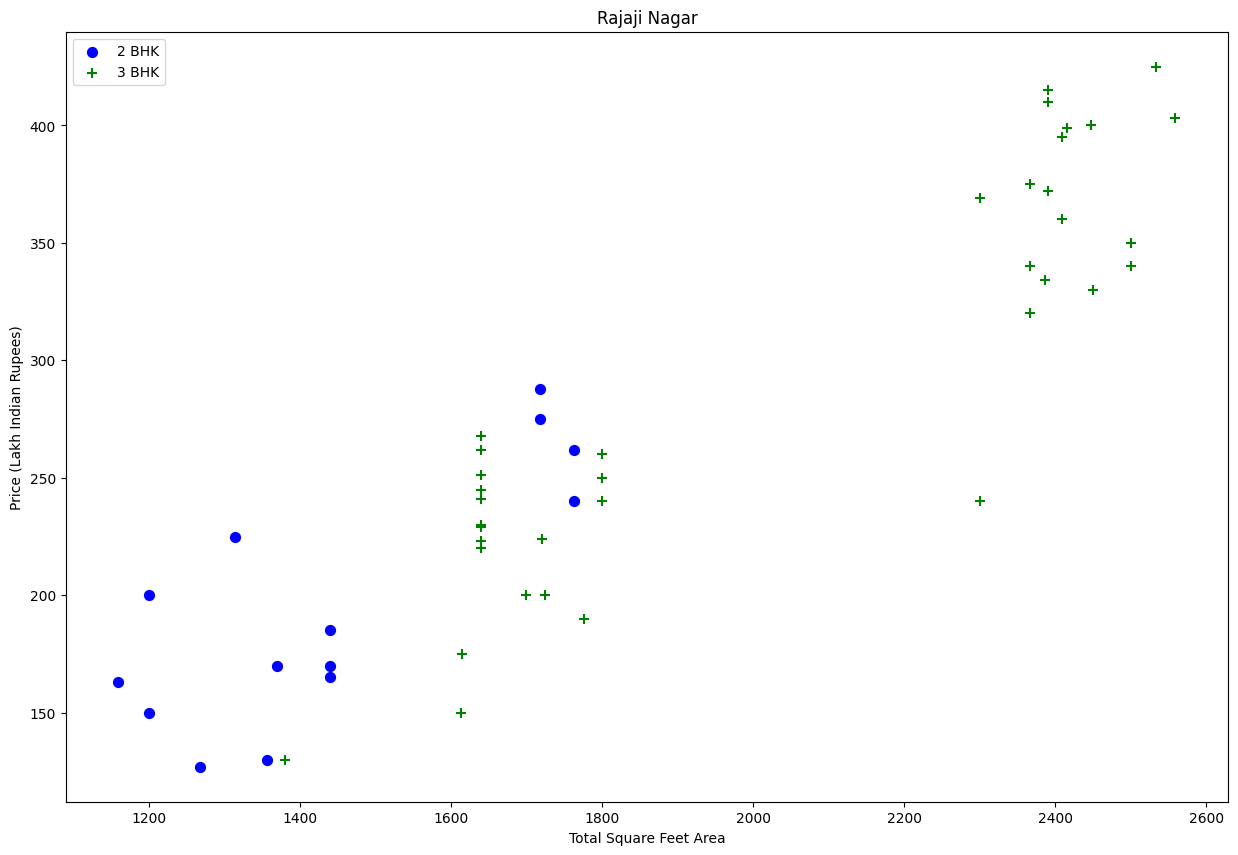

In [1296]:
#now we will verify about the bedrooms there are some homes that have more bedrooms than others with high price(in reality this is can be exceptable because other factures can influence in the price) but we should fix this
#so first we will draw a plot and do a comparison between homes with 2 bedrooms and 3 bedrroms home

def plot_scatter_chart(df,location):
    bhk2 = df[(df.location==location) & (df.bhk==2)]
    bhk3 = df[(df.location==location) & (df.bhk==3)]
    matplotlib.rcParams['figure.figsize'] = (15,10)
    plt.scatter(bhk2.total_sqft,bhk2.price,color='blue',label='2 BHK', s=50)
    plt.scatter(bhk3.total_sqft,bhk3.price,marker='+', color='green',label='3 BHK', s=50)
    plt.xlabel("Total Square Feet Area")
    plt.ylabel("Price (Lakh Indian Rupees)")
    plt.title(location)
    plt.legend()
    
plot_scatter_chart(df7,"Rajaji Nagar") #we see for this location some homes with two bedrooms are expensive that 3 bedrooms homes

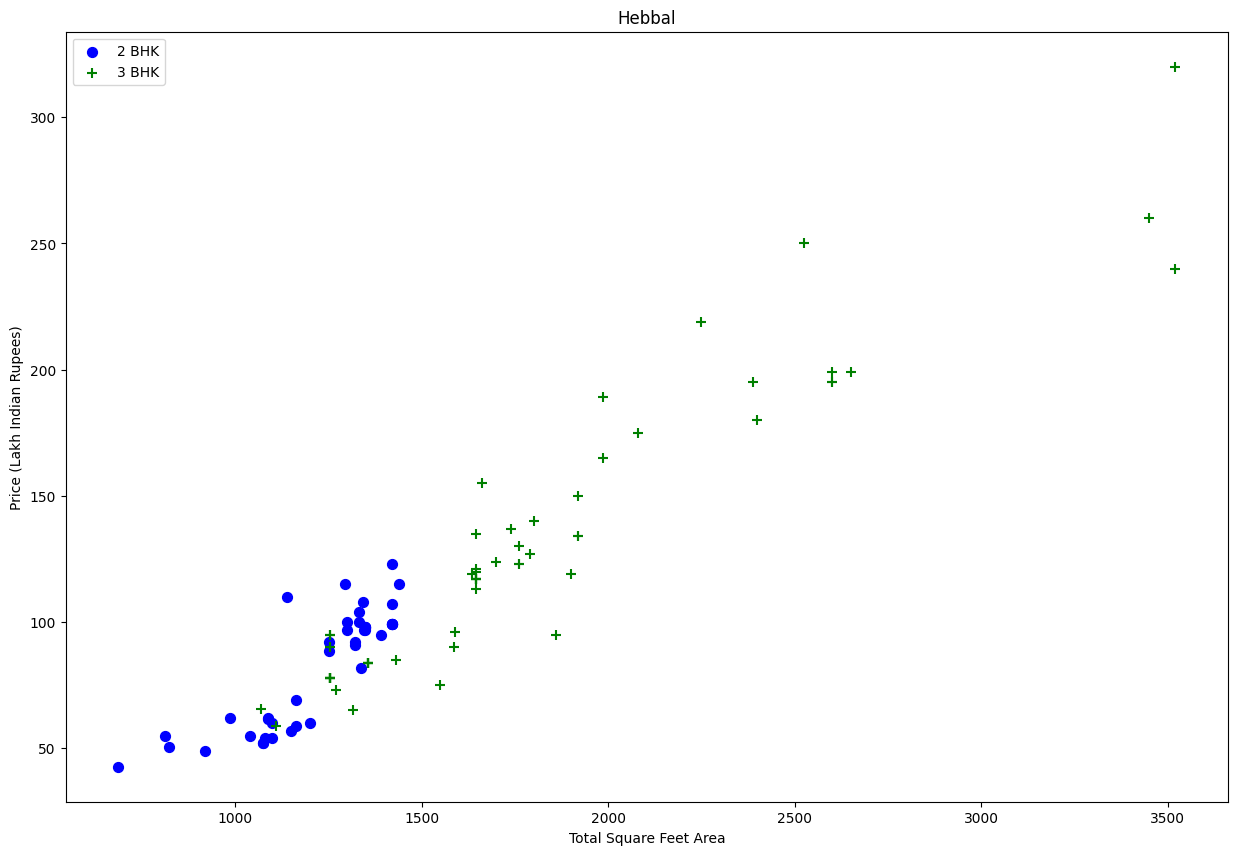

In [1297]:
plot_scatter_chart(df7,"Hebbal")#and this also show the same prblm

In [1298]:
def remove_bhk_outliers(df):
    exclude_indices = np.array([])
    for location, location_df in df.groupby('location'):
        bhk_stats = {}
        for bhk, bhk_df in location_df.groupby('bhk'):
            bhk_stats[bhk] = {
                'mean': np.mean(bhk_df.price_per_sqft),
                'std': np.std(bhk_df.price_per_sqft),
                'count': bhk_df.shape[0]
            }
        for bhk, bhk_df in location_df.groupby('bhk'):
            stats = bhk_stats.get(bhk-1)
            if stats and stats['count']>5:
                exclude_indices = np.append(exclude_indices, bhk_df[bhk_df.price_per_sqft<(stats['mean'])].index.values)
    return df.drop(exclude_indices,axis='index')
df8 = remove_bhk_outliers(df7)
# df8 = df7.copy()
df8.shape

#The idea is we gonna remove the homes for example that had 2 bedrooms which their price per sqft is less than the mean of the previous one (with 1 bedroom)

(7342, 7)

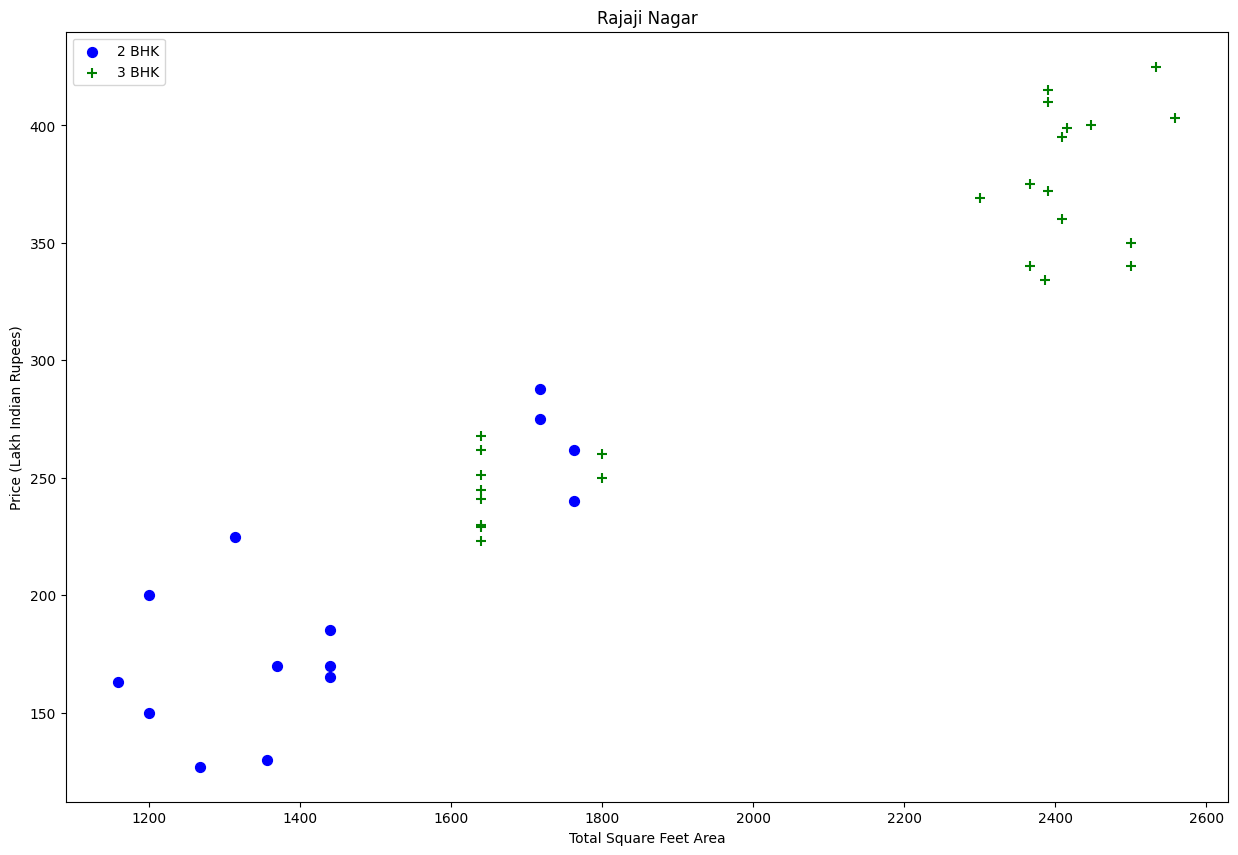

In [1299]:
plot_scatter_chart(df8,"Rajaji Nagar")

Text(0, 0.5, 'Count')

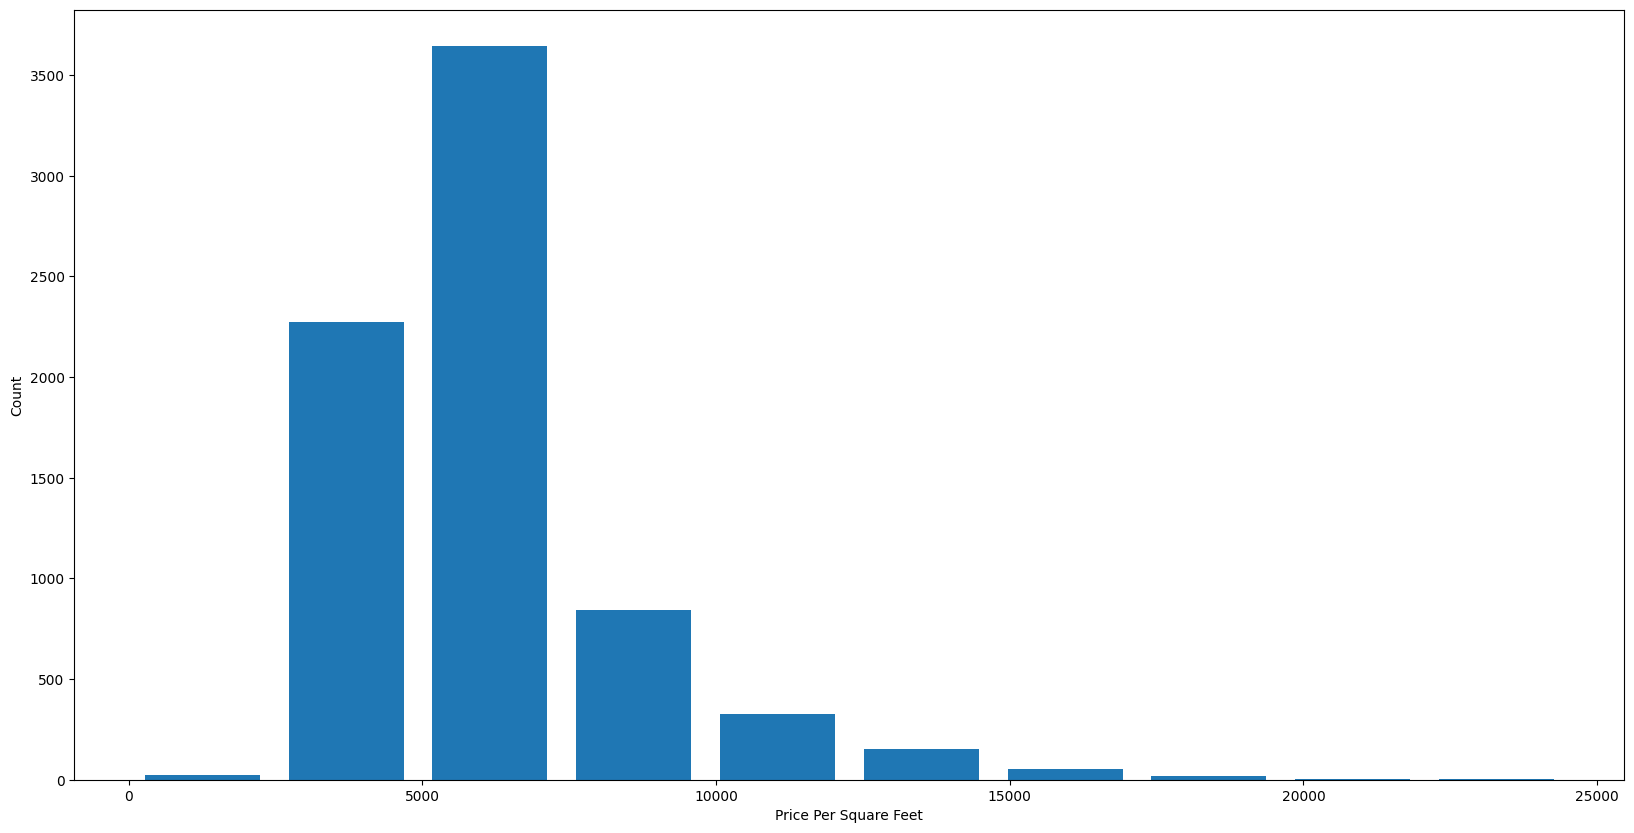

In [1300]:
import matplotlib
matplotlib.rcParams["figure.figsize"] = (20,10)
plt.hist(df8.price_per_sqft,rwidth=0.8)
plt.xlabel("Price Per Square Feet")
plt.ylabel("Count")

In [1301]:
df8.bath.unique() #there are some houses with more than 4 bathrooms (to 16!!)

array([ 4.,  3.,  2.,  5.,  1.,  8.,  6.,  7.,  9., 12., 16., 13.])

Text(0, 0.5, 'Count')

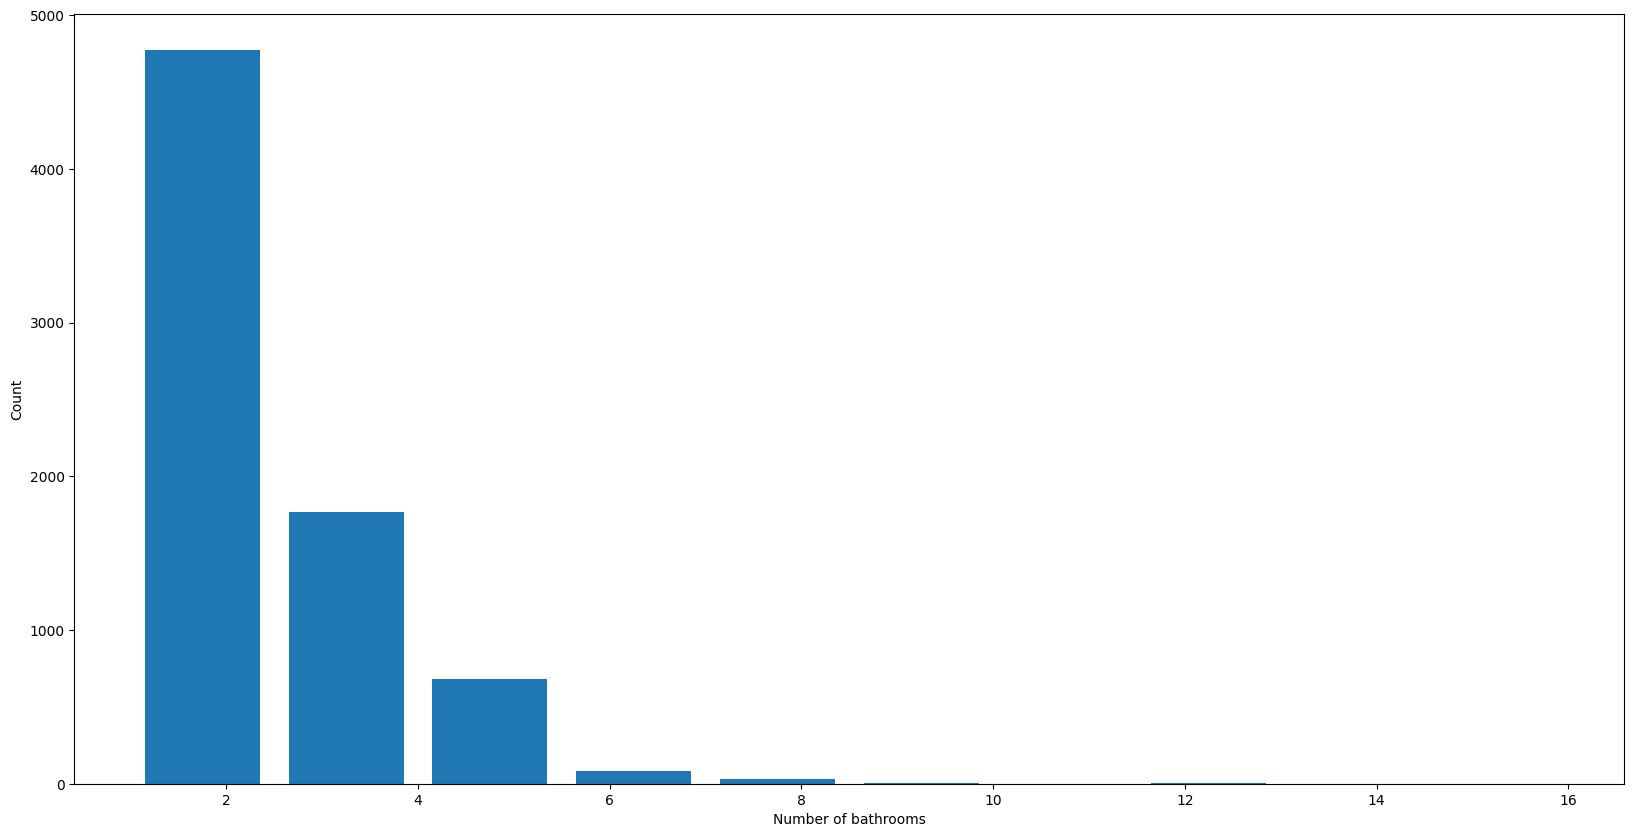

In [1302]:
plt.hist(df8.bath,rwidth=0.8)
plt.xlabel("Number of bathrooms")
plt.ylabel("Count")

In [1303]:
df8[df8.bath>df8.bhk+2] #let's see the house that have baths more than the rooms!!(why +2: ynjm ykoun 3ndna F2 fiha bath fi room w wa7d ga3 3la bara)

,location,size,total_sqft,bath,price,bhk,price_per_sqft
1632,Chikkabanavar,4 Bedroom,2460.0,7.0,80.0,4,3252.032520
5252,Nagasandra,4 Bedroom,7000.0,8.0,450.0,4,6428.571429
6727,Thanisandra,3 BHK,1806.0,6.0,116.0,3,6423.034330
8430,other,6 BHK,11338.0,9.0,1000.0,6,8819.897689


In [1304]:
df9 = df8[df8.bath<df8.bhk+2]
df9.shape

(7264, 7)

**# Finally we can  start with building the ML model**

In [1305]:
df10 = df9.drop(['size', 'price_per_sqft'], axis='columns')
df10.head()

,location,total_sqft,bath,price,bhk
0,1st Block Jayanagar,2850.0,4.0,428.0,4
1,1st Block Jayanagar,1630.0,3.0,194.0,3
2,1st Block Jayanagar,1875.0,2.0,235.0,3
3,1st Block Jayanagar,1200.0,2.0,130.0,3
4,1st Block Jayanagar,1235.0,2.0,148.0,2


In [1306]:
dummies = pd.get_dummies(df10.location)
dummies.head()

,1st Block Jayanagar,1st Phase JP Nagar,2nd Phase Judicial Layout,2nd Stage Nagarbhavi,5th Block Hbr Layout,5th Phase JP Nagar,6th Phase JP Nagar,7th Phase JP Nagar,8th Phase JP Nagar,9th Phase JP Nagar,...,Vishveshwarya Layout,Vishwapriya Layout,Vittasandra,Whitefield,Yelachenahalli,Yelahanka,Yelahanka New Town,Yelenahalli,Yeshwanthpur,other
0,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [1307]:
df11 = pd.concat([df10, dummies.drop('other', axis='columns')], axis='columns')
df11.head()

,location,total_sqft,bath,price,bhk,1st Block Jayanagar,1st Phase JP Nagar,2nd Phase Judicial Layout,2nd Stage Nagarbhavi,5th Block Hbr Layout,...,Vijayanagar,Vishveshwarya Layout,Vishwapriya Layout,Vittasandra,Whitefield,Yelachenahalli,Yelahanka,Yelahanka New Town,Yelenahalli,Yeshwanthpur
0,1st Block Jayanagar,2850.0,4.0,428.0,4,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,1st Block Jayanagar,1630.0,3.0,194.0,3,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,1st Block Jayanagar,1875.0,2.0,235.0,3,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,1st Block Jayanagar,1200.0,2.0,130.0,3,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,1st Block Jayanagar,1235.0,2.0,148.0,2,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [1308]:
df12 = df11.drop('location', axis='columns')
df12.shape

(7264, 245)

In [1309]:
X = df12.drop('price', axis='columns')
X.head()

,total_sqft,bath,bhk,1st Block Jayanagar,1st Phase JP Nagar,2nd Phase Judicial Layout,2nd Stage Nagarbhavi,5th Block Hbr Layout,5th Phase JP Nagar,6th Phase JP Nagar,...,Vijayanagar,Vishveshwarya Layout,Vishwapriya Layout,Vittasandra,Whitefield,Yelachenahalli,Yelahanka,Yelahanka New Town,Yelenahalli,Yeshwanthpur
0,2850.0,4.0,4,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,1630.0,3.0,3,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,1875.0,2.0,3,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,1200.0,2.0,3,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,1235.0,2.0,2,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [1310]:
y = df12.price
y.head()

0    428.0
1    194.0
2    235.0
3    130.0
4    148.0
Name: price, dtype: float64

In [1311]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=10)


In [1312]:
from sklearn.linear_model import LinearRegression
lr_clf = LinearRegression()
lr_clf.fit(X_train, y_train)
lr_clf.score(X_test, y_test)

-230.37903188202128

In [1313]:
from sklearn.model_selection import ShuffleSplit
from sklearn.model_selection import cross_val_score

cv = ShuffleSplit(n_splits=5, test_size=0.2, random_state=0)
# ShuffleSplit in scikit-learn is a cross-validation strategy that splits your dataset into random train/test partitions multiple times, shuffling the data each time.
cross_val_score(LinearRegression(), X, y, cv=cv)

array([0.47391663, 0.62366601, 0.53031201, 0.69733202, 0.64266013])

In [1314]:
# from sklearn.model_selection import GridSearchCV

# from sklearn.linear_model import Lasso
# from sklearn.tree import DecisionTreeRegressor
# from sklearn.ensemble import RandomForestRegressor

# def find_best_model_using_gridsearchcv(X,y):
    
#     algos = {
#       'linear_regression': {
#         'model': LinearRegression(),
#         'params': {
#             'fit_intercept': [True, False]
#         }
#       },
#       'lasso': {
#         'model': Lasso(),
#         'params': {
#             'alpha': [1, 2],
#             'selection': ['random', 'cyclic']
#         }
#       },
#       'decision_tree': {
#         'model': DecisionTreeRegressor(),
#         'params': {
#             'criterion': ['squared_error', 'friedman_mse'],
#             'splitter': ['best', 'random']
#         }
#       },
#       'random_forest': {
#         'model': RandomForestRegressor(),
#         'params': {
#             'n_estimators': [50, 100],
#             'criterion': ['squared_error'],
#             'max_features': [ 'sqrt', 'log2'],
#             'bootstrap': [True]
#         }
#       }
#     }

#     scores = []
#     cv = ShuffleSplit(n_splits=5, test_size=0.2, random_state=0)
#     for algo_name, config in algos.items():
#         gs =  GridSearchCV(config['model'], config['params'], cv=cv, return_train_score=False)
#         gs.fit(X,y)
#         scores.append({
#             'model': algo_name,
#             'best_score': gs.best_score_,
#             'best_params': gs.best_params_
#         })

#     return pd.DataFrame(scores,columns=['model','best_score','best_params'])

# find_best_model_using_gridsearchcv(X,y)

# #well i change the function of the covert_to_sqft acording to the tutorial if i made all the case the decision tree had the best score 
#commentit pcq ma yt9alich mohim Random forest ta3lt kthar minhm

In [1315]:
from sklearn.ensemble import RandomForestRegressor
tr_clf = RandomForestRegressor(bootstrap=True, criterion='squared_error', n_estimators=50, max_features='sqrt')
tr_clf.fit(X_train, y_train)
tr_clf.score(X_test, y_test)

0.8112684834154128

In [1316]:

def predict_price(location,sqft,bath,bhk, model):    
    loc_index = np.where(X.columns==location)[0][0]

    x = np.zeros(len(X.columns))
    x[0] = sqft
    x[1] = bath
    x[2] = bhk
    if loc_index >= 0:
        x[loc_index] = 1

    return model.predict([x])[0]

In [1317]:
predict_price('1st Phase JP Nagar',1000, 2, 2, lr_clf)

C:\Users\admin\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


88.64107735504611

In [1318]:
predict_price('1st Phase JP Nagar',1000, 2, 2, tr_clf)

C:\Users\admin\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


80.68101226551227

In [1319]:
predict_price('Indira Nagar',1000, 2, 2, lr_clf)

C:\Users\admin\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


170.10653001440323

In [1320]:
predict_price('Indira Nagar',1000, 2, 2, tr_clf)

C:\Users\admin\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


107.4676818181818

In [1321]:
predict_price('Indira Nagar',1000, 3, 3, tr_clf)

C:\Users\admin\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


200.31333333333336

In [1322]:
predict_price('1st Phase JP Nagar',1000, 3, 3, tr_clf)

C:\Users\admin\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


129.08

#### **Export the tested model to a pickle file**

In [1323]:
import pickle
with open('banglore_home_prices_model.pickle','wb') as f:
    pickle.dump(tr_clf,f)

#### **Export location and column information to a file that will be useful later on in our prediction application**

In [1324]:

import json
columns = {
    'data_columns' : [col.lower() for col in X.columns]
}
with open("columns.json","w") as f:
    f.write(json.dumps(columns))